# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

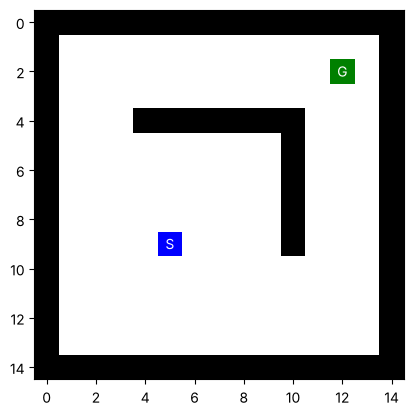

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## Run the Algorithm

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

## Bài 1 – Ghi nhận và phân tích kết quả

Hàm mục tiêu là khoảng cách Manhattan tới đích $h(n) = |r_n - r_G| + |c_n - c_G|$ (càng nhỏ càng tốt). Cell dưới đây chạy lại thuật toán và ghi nhận *toàn bộ quỹ đạo* để so sánh vị trí dừng với đích G và vẽ đường đi.

Xuất phát S = (9, 5), đích G = (2, 12)
Vị trí dừng = (5, 9) sau 8 bước;  h(S) = 14,  h(dừng) = 6
Đã đến được đích G? False


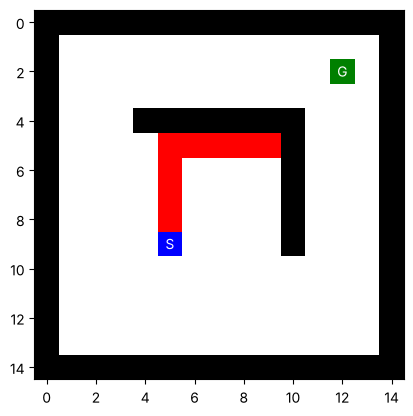

In [8]:
def local_search_path(maze):
    """Giống local_search() nhưng trả về toàn bộ danh sách các ô đã đi qua."""
    goal = mh.find_pos(maze, "G")
    current = tuple(int(x) for x in mh.find_pos(maze, "S"))
    path = [current]
    while True:
        neighbors = [tuple(int(x) for x in n[1]) for n in expand(maze, current)]
        obj = [manhattan(n, goal) for n in neighbors]
        best = min(obj)
        if best < manhattan(current, goal):           # chỉ đi tiếp nếu cải thiện
            current = neighbors[obj.index(best)]
            path.append(current)
        else:
            return path

set_order("NESW", random=False, verbose=False)
start = tuple(int(x) for x in mh.find_pos(maze, "S"))
goal = tuple(int(x) for x in mh.find_pos(maze, "G"))
path = local_search_path(maze)
stop = path[-1]
print(f"Xuất phát S = {start}, đích G = {goal}")
print(f"Vị trí dừng = {stop} sau {len(path) - 1} bước;  h(S) = {manhattan(start, goal)},  h(dừng) = {manhattan(stop, goal)}")
print("Đã đến được đích G?", stop == goal)

# vẽ đường đi (P) trên mê cung
maze_path = maze.copy()
for p in path[1:]:
    maze_path[p[0], p[1]] = "P"
mh.show_maze(maze_path)

**Giải thích vì sao dừng mà chưa tới đích.** Thuật toán chỉ nhìn các ô láng giềng và chỉ đi tiếp nếu $h$ giảm. Từ S nó đi lên rồi sang phải theo hướng làm $h$ giảm, nhưng đích G nằm *phía bên kia bức tường* chữ L. Tại ô dừng, hai ô láng giềng còn lại (đi xuống và sang trái) đều có $h$ lớn hơn, còn hai ô còn lại (lên và sang phải) là tường. Vì vậy không có láng giềng nào tốt hơn và thuật toán kết luận đã tới cực trị: đây là **cực trị cục bộ** (local optimum) – tốt hơn mọi ô lân cận nhưng không phải tối ưu toàn cục ($h=0$ tại G). Để tới G, đường đi bắt buộc phải *đi xa đích hơn trước khi lại gần* (vòng qua tường), điều mà hill climbing không bao giờ làm.

### Thay đổi thứ tự xét hướng và ngẫu nhiên hóa

Thử tất cả $4! = 24$ thứ tự xét hướng và 200 lần chạy với thứ tự ngẫu nhiên (`random=True`) để xem kết quả có thay đổi không.

In [9]:
import itertools
from collections import Counter

# 1) toàn bộ 24 thứ tự cố định
fixed = Counter()
for perm in itertools.permutations("NESW"):
    set_order("".join(perm), random=False, verbose=False)
    fixed[local_search_path(maze)[-1]] += 1

# 2) thứ tự ngẫu nhiên ở mỗi bước (chạy 200 lần)
rand = Counter()
np.random.seed(1234)
set_order("NESW", random=True, verbose=False)
for _ in range(200):
    rand[local_search_path(maze)[-1]] += 1

print("24 thứ tự cố định -> vị trí dừng (số thứ tự):", dict(fixed))
print("200 lần chạy ngẫu nhiên -> vị trí dừng (số lần):", dict(rand))
set_order("NESW", random=False, verbose=False)      # khôi phục cấu hình mặc định

24 thứ tự cố định -> vị trí dừng (số thứ tự): {(5, 9): 24}
200 lần chạy ngẫu nhiên -> vị trí dừng (số lần): {(5, 9): 200}


**Nhận xét.** Dù thay đổi thứ tự xét hướng hay ngẫu nhiên hóa, thuật toán luôn dừng ở *cùng một ô* và không bao giờ đến được G. Thứ tự/ngẫu nhiên chỉ ảnh hưởng khi có nhiều láng giềng cùng giá trị $h$ (hòa), và chỉ làm đổi *đường đi*, không làm đổi *điểm dừng*, vì mọi đường đi giảm $h$ từ S đều dẫn vào cùng một "túi" chắn bởi bức tường. Muốn thoát phải thay đổi thuật toán (random restart từ ô khác, simulated annealing cho phép bước xấu) hoặc hàm mục tiêu.

### Random restart trên mê cung

Thử khởi động lại từ các ô trống ngẫu nhiên (thay vì luôn từ S) để xem hill climbing có cơ hội đến được đích hay không.

In [10]:
free = [(r, c) for r in range(maze.shape[0]) for c in range(maze.shape[1]) if maze[r, c] in (" ", "S")]
reached = Counter()
for (r, c) in free:
    m = maze.copy()
    m[start] = " "; m[r, c] = "S"                    # đặt điểm xuất phát mới
    reached[tuple(int(x) for x in local_search_path(m)[-1]) == goal] += 1
print(f"{len(free)} ô xuất phát; hill climbing đến được G từ {reached[True]} ô ({100 * reached[True] / len(free):.0f}%), kẹt ở cực trị cục bộ từ {reached[False]} ô.")

156 ô xuất phát; hill climbing đến được G từ 102 ô (65%), kẹt ở cực trị cục bộ từ 54 ô.


**Nhận xét.** Từ khoảng hai phần ba số ô xuất phát hill climbing đến được G; các ô còn lại vẫn bị kẹt tại những cực trị cục bộ nằm sát bức tường (nơi mọi láng giềng đều xa đích hơn). Random restart vì vậy làm tăng xác suất thành công, đúng như mong đợi, nhưng không bảo đảm: kết quả phụ thuộc vào việc điểm xuất phát có nằm trong "vùng hút" của cực trị toàn cục hay không.

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!